## 1. Import Library yang Dibutuhkan
Memanggil library utama untuk pemrosesan citra digital dan analisis data:
- **`cv2` (OpenCV)**: Membaca gambar, manipulasi channel warna, konversi grayscale, dan deteksi tepi (Canny & Laplacian).
- **`skimage.feature`**: Ekstraksi fitur tekstur spasial GLCM (*Gray-Level Co-occurrence Matrix*).
- **`numpy`**: Perhitungan statistik matriks dan array piksel (mean, standar deviasi).
- **`pandas`**: Mengelola dataset hasil ekstraksi ke dalam bentuk tabular (DataFrame) dan ekspor ke file CSV.
- **`matplotlib.pyplot`**: Visualisasi komparasi citra gambar.

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from skimage.feature import graycomatrix, graycoprops
import matplotlib.pyplot as plt

## 2. Konfigurasi Direktori Dataset dan Kelas Target
Mendefinisikan lokasi folder dataset dan kategori kelas yang akan diklasifikasikan:
- `BASE_DIR = "../data/"`: Jalur direktori utama tempat folder gambar disimpan.
- `CLASSES = ["berantakan", "rapi"]`: Dua subfolder label kelas target.
- Pendekatan ini membuat kode lebih fleksibel, terstruktur, dan menghindari kesalahan *hardcoded path*.

In [4]:
# ini direktori nya
BASE_DIR = "../data/"

# di dalam direktori ada sub folder baru yaitu berantakan dan rapi
CLASSES = ["berantakan", "rapi"]

## 3. Ekstraksi Fitur Citra (Warna, Tepi, dan Tekstur GLCM)
Melakukan perulangan (*looping*) ke seluruh gambar pada folder kelas untuk mengekstrak **12 fitur digital**:

1. **Fitur Warna (6 Fitur)**:
   - `mean_red`, `mean_green`, `mean_blue`: Nilai rata-rata intensitas tiap kanal warna RGB.
   - `std_red`, `std_green`, `std_blue`: Standar deviasi (variasi kontras sebaran warna) tiap kanal RGB.
2. **Fitur Tepi / Kontur (2 Fitur)**:
   - `edge_laplacian_variance`: Mengukur tingkat kerumitan dan ketajaman gradien garis detail gambar.
   - `edge_density`: Rasio kepadatan piksel tepi hasil filter *Canny Edge Detector*.
3. **Fitur Tekstur Spasial GLCM (4 Fitur)**:
   - `glcm_contrast`: Perbedaan intensitas antar piksel tetangga (menunjukkan kekasaran tekstur).
   - `glcm_homogeneity`: Keseragaman pola piksel bertetangga (tinggi jika penataan rapi/seragam).
   - `glcm_energy`: Keteraturan tekstur citra.
   - `glcm_correlation`: Tingkat keterikatan linear antar piksel bertetangga.

In [5]:
data_fitur = []

for label in CLASSES:
  folder_path = os.path.join(BASE_DIR, label)

  file_list = os.listdir(folder_path)

  for filename in file_list:
    if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
      continue

    img_path = os.path.join(folder_path, filename)
    img = cv2.imread(img_path)

    if img is None:
      print(f"Gagal membaca gambar : {img_path}")
      continue

    # dijadikan grayscale buat penambahan fitur
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # laplacian mengukur kerumitan detail garis
    laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

    # canny edge mengukur seberapa banyak garis tepi  di gambar
    edges = cv2.Canny(gray, 100, 200)
    edge_density = np.sum(edges > 0) / edges.size

    # menghitung matriks GLCM
    glcm = graycomatrix(gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)

    # megambil 4 nilai statistik dari GLCM
    glcm_contrast = graycoprops(glcm, 'contrast')[0, 0]
    glcm_homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    glcm_energy = graycoprops(glcm, 'energy')[0, 0]
    glcm_correlation = graycoprops(glcm, 'correlation')[0, 0]

    b_channel = img[:, :, 0]
    g_channel = img[:, :, 1]
    r_channel = img[:, :, 2]

    mean_r = np.mean(r_channel)
    std_r = np.std(r_channel)

    mean_g = np.mean(g_channel)
    std_g = np.std(g_channel)

    mean_b = np.mean(b_channel)
    std_b = np.std(b_channel)

    data_fitur.append({
      "filename" : filename,
      "label" : label,

      # fitur untuk warna
      "mean_red":round(mean_r, 4),
      "mean_green":round(mean_g, 4),
      "mean_blue":round(mean_b, 4),
      "std_red":round(std_r, 4),
      "std_green":round(std_g, 4),
      "std_blue":round(std_b, 4),
      
      # fitur untuk tepi
      "edge_laplacian_variance":round(laplacian_var, 4),
      "edge_density":round(edge_density, 4),

      # fitur untuk tekstur GLCM
      "glcm_contrast":round(glcm_contrast, 4),
      "glcm_homogeneity":round(glcm_homogeneity, 4),
      "glcm_energy":round(glcm_energy, 4),
      "glcm_correlation":round(glcm_correlation, 4),
    })

## 4. Konversi Dataframe dan Penyimpanan ke Format CSV
Mengubah kumpulan data fitur yang telah diekstrak ke dalam tabel terstruktur:
- `pd.DataFrame(data_fitur)`: Menyatukan seluruh nilai numerik, nama file, dan label kelas ke dalam struktur DataFrame Pandas.
- `df.to_csv(output_csv, index=False)`: Menyimpan dataset fitur ke file `.csv` agar siap digunakan sebagai input algoritma Machine Learning.

In [10]:
df = pd.DataFrame(data_fitur)
output_csv = "../hasil_ekstraksi/fitur_rgb_std.csv"
df.to_csv(output_csv, index=False)

## 5. Inspeksi dan Validasi 5 Baris Pertama Data Fitur
Menampilkan 5 data teratas (`df.head()`) untuk memvalidasi:
- Seluruh 12 kolom fitur (RGB, Edge, GLCM) berhasil diekstrak dan bernilai numerik valid.
- Kolom identitas (`filename` dan `label`) terasosiasi dengan tepat sesuai kelas gambarnya.

In [11]:
df.head()

,filename,label,mean_red,mean_green,mean_blue,std_red,std_green,std_blue,edge_laplacian_variance,edge_density,glcm_contrast,glcm_homogeneity,glcm_energy,glcm_correlation
0,berantakan_001.jpg,berantakan,133.0250,121.0971,109.7106,55.4688,53.8199,54.1130,503.4941,0.0515,103.5193,0.4845,0.0335,0.9819
1,berantakan_002.jpg,berantakan,117.2852,109.3012,99.4207,64.9177,61.6087,57.2564,425.7798,0.0531,95.7767,0.3893,0.0284,0.9874
2,berantakan_003.jpg,berantakan,160.6719,142.4771,134.9819,47.2719,59.3187,67.8100,13.6370,0.0099,11.8089,0.6836,0.0808,0.9980
3,berantakan_004.jpg,berantakan,151.9835,138.3797,131.6321,62.3337,71.1531,74.5744,212.7481,0.0417,69.2484,0.5681,0.0973,0.9923
4,berantakan_005.jpg,berantakan,133.8936,112.9759,103.2898,53.9008,57.0202,63.4242,53.3302,0.0181,30.1308,0.4508,0.0312,0.9948


## 6. Visualisasi Citra: Sampel Rapi vs Berantakan (RGB & Grayscale)
Menampilkan visualisasi komparasi gambar sepatu dari kedua kelas dalam format Grid 2x2 secara dinamis:
- **Baris 1**: Sampel citra kelas **Rapi** dalam format warna (RGB) dan derajat keabuan (Grayscale).
- **Baris 2**: Sampel citra kelas **Berantakan** dalam format RGB dan Grayscale.
- Visualisasi ini membantu menganalisis perbedaan posisi, orientasi arah, dan sebaran bayangan antar kelas secara kualitatif.

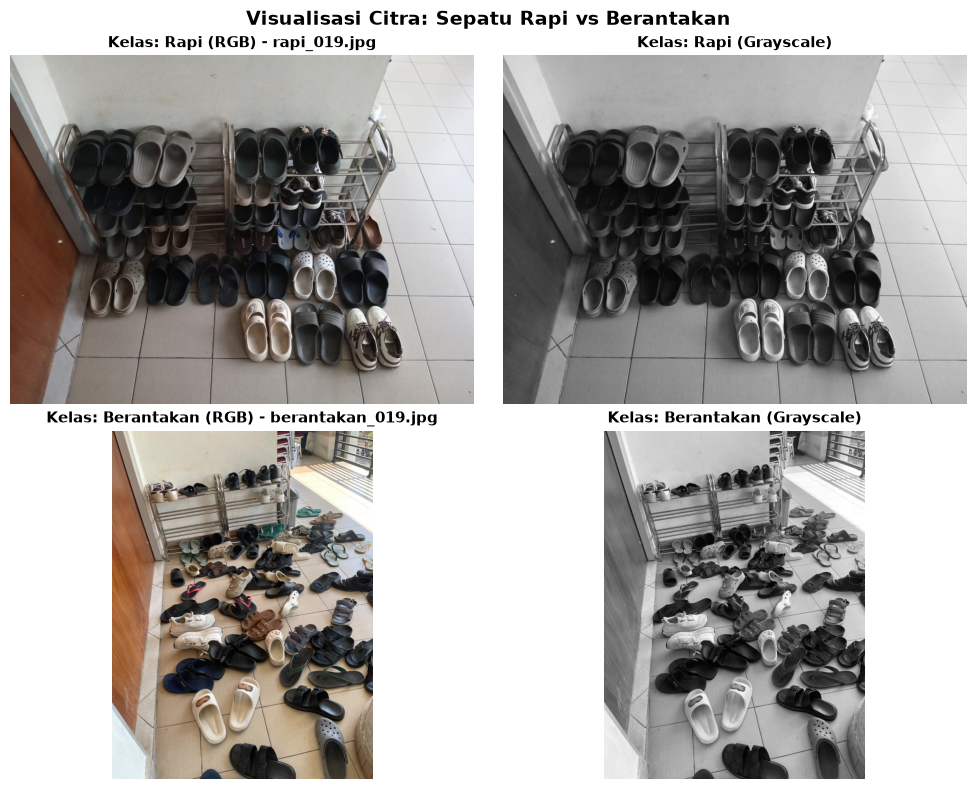

In [23]:
# 1. Ambil contoh file secara otomatis menggunakan BASE_DIR yang sudah didefinisikan
file_rapi = [f for f in os.listdir(os.path.join(BASE_DIR, "rapi")) if f.lower().endswith((".jpg", ".jpeg", ".png"))][18]
file_berantakan = [f for f in os.listdir(os.path.join(BASE_DIR, "berantakan")) if f.lower().endswith((".jpg", ".jpeg", ".png"))][18]

path_rapi = os.path.join(BASE_DIR, "rapi", file_rapi)
path_berantakan = os.path.join(BASE_DIR, "berantakan", file_berantakan)

# 2. Baca gambar
img_rapi_bgr = cv2.imread(path_rapi)
img_berantakan_bgr = cv2.imread(path_berantakan)

# 3. Konversi ke RGB (warna) dan Grayscale (hitam-putih)
rapi_rgb = cv2.cvtColor(img_rapi_bgr, cv2.COLOR_BGR2RGB)
rapi_gray = cv2.cvtColor(img_rapi_bgr, cv2.COLOR_BGR2GRAY)

berantakan_rgb = cv2.cvtColor(img_berantakan_bgr, cv2.COLOR_BGR2RGB)
berantakan_gray = cv2.cvtColor(img_berantakan_bgr, cv2.COLOR_BGR2GRAY)

# 4. Plotting dalam Grid 2 Baris x 2 Kolom
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Baris 1: Kelas Rapi
axes[0, 0].imshow(rapi_rgb)
axes[0, 0].set_title(f"Kelas: Rapi (RGB) - {file_rapi}", fontsize=11, fontweight="bold")
axes[0, 0].axis("off")

axes[0, 1].imshow(rapi_gray, cmap="gray")
axes[0, 1].set_title("Kelas: Rapi (Grayscale)", fontsize=11, fontweight="bold")
axes[0, 1].axis("off")

# Baris 2: Kelas Berantakan
axes[1, 0].imshow(berantakan_rgb)
axes[1, 0].set_title(f"Kelas: Berantakan (RGB) - {file_berantakan}", fontsize=11, fontweight="bold")
axes[1, 0].axis("off")

axes[1, 1].imshow(berantakan_gray, cmap="gray")
axes[1, 1].set_title("Kelas: Berantakan (Grayscale)", fontsize=11, fontweight="bold")
axes[1, 1].axis("off")

plt.suptitle("Visualisasi Citra: Sepatu Rapi vs Berantakan", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()